# Sentinel-2 on ellipsoidal HEALPix: find, open, extract and plot at several resolutions

This notebook reads Sentinel-2 data that GRID4EARTH converted to the HEALPix grid on the WGS84 ellipsoid, straight from the public object store. It shows how to

1. **find** the store that covers a place, in the STAC catalogue or from the place's coordinates alone,
2. **open** it with Xarray and decode its grid with xdggs,
3. **extract** the values at a point and over a region,
4. **plot** the same area at several resolutions, reading only the level you need.

**The data**: Sentinel-2B Level-2A (bottom-of-atmosphere reflectance) of 2026-08-12, relative orbit 51, between 45 and 49°N. The datatake is cut into one Zarr store per HEALPix *parent cell* at level 7 (about 50 km), and every store holds the reflectance at levels 20 (≈6 m, the 10 m bands) down to 12 (≈1.6 km).

Nothing is downloaded beforehand: each step reads only the chunks it needs over HTTPS.

In [1]:
import numpy as np
import xarray as xr
import xdggs  # noqa: F401  (registers the .dggs accessor)
import healpix_geo.nested as hpx
import healpix_plot
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from pystac_client import Client

# The reflectance is stored with the Sentinel-2 codecs of healpix-compress;
# zarr finds them through the package's entry points, so it only needs to be installed.
_ = xr.set_options(display_expand_attrs=False, display_expand_data_vars=False)

## 1. Find the store that covers a place

### In the STAC catalogue

Every store is an item of the GRID4EARTH STAC catalogue, so a search by place and date returns it, as for any other STAC collection. The `product` asset is the root of the Zarr store, and the item records the HEALPix parent cell the store covers.

In [2]:
lon, lat = 2.3499, 48.8530  # Notre-Dame de Paris

catalog = Client.open("https://stac-api.grid4earth.eu")
search = catalog.search(
    collections=["converted-healpix-tiled-sentinel-2-l2a-multires"],
    intersects={"type": "Point", "coordinates": [lon, lat]},
    datetime="2026-08-12",
)
item = next(search.items())
url = item.assets["product"].href
print(item.id)
print(f"level-{item.properties['g4e:healpix_parent_level']} cell {item.properties['g4e:healpix_parent_cell']}")
print(url)

converted-healpix-tiled-S2B_MSIL2A_20260812T104619_R051_O49269_L7_C11186_mean-l20-l12-hcc
level-7 cell 11186
https://data.grid4earth.eu/converted-healpix-tiled/sentinel-2-l2a-multires/mean-l20-l12-hcc/S2B_MSIL2A_20260812T104619_R051_O49269_L7_C11186.zarr


### From the coordinates alone

The catalogue is not even needed. In the nested HEALPix scheme, the parent of a cell is obtained by dropping two bits per level, and all the children of a cell have consecutive ids. The stores are named after their level-7 parent cell, so the coordinates of a place are enough to find its store: compute the level-7 cell that contains the point, on the WGS84 ellipsoid.

In [3]:
parent_level = 7
parent = int(hpx.lonlat_to_healpix(np.array([lon]), np.array([lat]), depth=parent_level, ellipsoid="WGS84")[0])

base = "https://data.grid4earth.eu/converted-healpix-tiled/sentinel-2-l2a-multires/mean-l20-l12-hcc"
assert url == f"{base}/S2B_MSIL2A_20260812T104619_R051_O49269_L7_C{parent}.zarr"
print(f"level-{parent_level} cell {parent}: the same store")

level-7 cell 11186: the same store


## 2. Open it

The store is a Zarr v3 hierarchy that follows the EOPF product structure. `measurements/reflectance` holds one group per HEALPix level. Each band starts at its native level (20 for the 10 m bands, 19 for the 20 m bands, 17 for the 60 m bands). Where ESA ships a band at a coarser resolution itself (for instance B02 to B04 at 20 m and 60 m), that copy is kept at the matching level; every other coarser value is the mean of its four children. The `native_refinement_level` attribute of each array says which level it comes from.

In [4]:
tree = xr.open_datatree(url, engine="zarr")
reflectance = tree["measurements/reflectance"]

for level in sorted(reflectance.children, key=int, reverse=True):
    ds = reflectance[level].to_dataset()
    bands = [name for name in ds.data_vars if name != "crs"]
    print(f"level {level:>2}: {ds.sizes['cells']:>10,} cells  {' '.join(bands)}")

level 20: 67,108,864 cells  b02 b03 b04 b08
level 19: 16,777,216 cells  b01 b02 b03 b04 b05 b06 b07 b08 b11 b12 b8a
level 18:  4,194,304 cells  b01 b02 b03 b04 b05 b06 b07 b08 b11 b12 b8a
level 17:  1,048,576 cells  b01 b02 b03 b04 b05 b06 b07 b08 b09 b11 b12 b8a
level 16:    262,144 cells  b01 b02 b03 b04 b05 b06 b07 b08 b09 b11 b12 b8a
level 15:     65,536 cells  b01 b02 b03 b04 b05 b06 b07 b08 b09 b11 b12 b8a
level 14:     16,384 cells  b01 b02 b03 b04 b05 b06 b07 b08 b09 b11 b12 b8a
level 13:      4,096 cells  b01 b02 b03 b04 b05 b06 b07 b08 b09 b11 b12 b8a
level 12:      1,024 cells  b01 b02 b03 b04 b05 b06 b07 b08 b09 b11 b12 b8a


xdggs reads the grid description from the group's `dggs` attribute (the Zarr DGGS convention: HEALPix, nested, level, WGS84 ellipsoid) and attaches a DGGS index to the cell ids. The values are bottom-of-atmosphere reflectance (the `units` attribute still says `digital_counts`, inherited from the EOPF input; this will be fixed).

In [5]:
level14 = reflectance["14"].to_dataset().dggs.decode(convention="zarr")
print(level14.dggs.grid_info)
level14

HealpixInfo(level=14, ellipsoid=Ellipsoid(semimajor_axis=6378137.0, inverse_flattening=298.257223563, name='wgs84'), indexing_scheme='nested')


<xarray.Dataset> Size: 2MB
Dimensions:   (cells: 16384)
Coordinates:
  * cell_ids  (cells) uint64 131kB 183271424 183271425 ... 183287806 183287807
Dimensions without coordinates: cells
Data variables: (13)
Indexes:
    cell_ids  HealpixIndex(level=14, indexing_scheme=nested, kind=pandas)

## 3. Extract

### A point

Each store holds *every* cell of its parent at every level, in nested order. The position of a cell inside a level is therefore its id minus the id of the first child of the parent: no search is needed, and only the chunk that contains the cell is read.

In [6]:
def positions(cell, cell_level, level):
    """Positions, inside this store at `level`, of the cells of `cell` (given at `cell_level`)."""
    first_in_store = parent << 2 * (level - parent_level)
    start = (cell << 2 * (level - cell_level)) - first_in_store
    return slice(start, start + 4 ** (level - cell_level))


cell20 = int(hpx.lonlat_to_healpix(np.array([lon]), np.array([lat]), depth=20, ellipsoid="WGS84")[0])
point = reflectance["20"].to_dataset().isel(cells=positions(cell20, 20, 20)).load()
{band: round(float(point[band][0]), 4) for band in ["b02", "b03", "b04", "b08"]}

{'b02': 0.1469, 'b03': 0.1334, 'b04': 0.1404, 'b08': 0.1337}

Level 19 (≈12 m) has all the bands except B09 and B10, so it gives the whole spectrum of the place. The band wavelengths come from the STAC metadata stored at the root of the store.

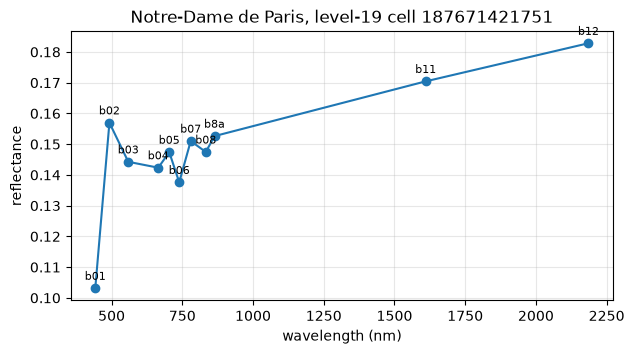

In [7]:
bands = tree.attrs["stac_discovery"]["properties"]["bands"]
wavelength = {b["name"]: b["eo:center_wavelength"] for b in bands}

cell19 = cell20 >> 2
pixel = reflectance["19"].to_dataset().isel(cells=positions(cell19, 19, 19)).load()
names = sorted((name for name in pixel.data_vars if name in wavelength), key=wavelength.get)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot([wavelength[n] * 1000 for n in names], [float(pixel[n][0]) for n in names], "o-")
for n in names:
    ax.annotate(n, (wavelength[n] * 1000, float(pixel[n][0])), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)
ax.set(xlabel="wavelength (nm)", ylabel="reflectance", title=f"Notre-Dame de Paris, level-19 cell {cell19}")
ax.grid(alpha=0.3)

### A region

A region is a cell of a coarser level. The level-11 cell around Notre-Dame (about 3 km wide) has 4⁹ = 262,144 children at level 20, again consecutive, and that is exactly one chunk of the store: one request per band.

In [8]:
region_level = 11
region = cell20 >> 2 * (20 - region_level)
city = reflectance["20"].to_dataset()[["b02", "b03", "b04"]].isel(cells=positions(region, region_level, 20)).load()
print(f"level-{region_level} cell {region}: {city.sizes['cells']:,} cells at level 20")

level-11 cell 2863638: 262,144 cells at level 20


## 4. Plot at several resolutions

healpix-plot resamples HEALPix cells onto a regular image grid for matplotlib and cartopy. A true-colour image uses B04, B03 and B02 as red, green and blue.

For an overview of the whole 50 km store, level 14 (≈400 m, 16,384 cells) is plenty: there is no need to read the 67 million cells of level 20. To zoom in, read the finer levels only over the region.

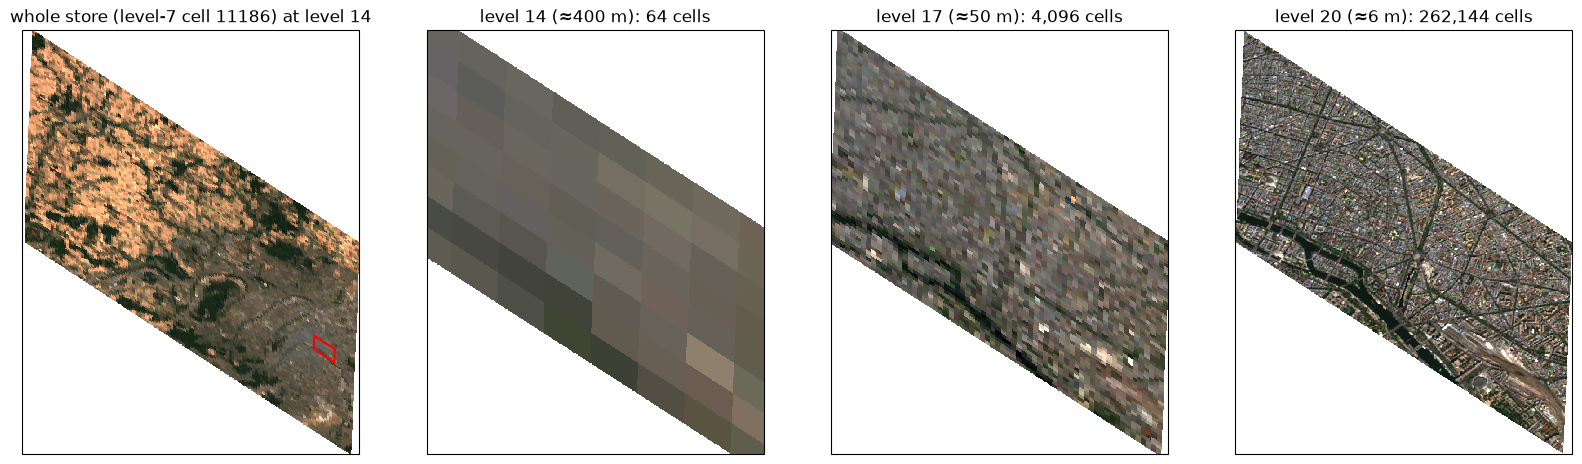

In [9]:
def true_colour(ds, gain=3.5):
    return np.clip(np.stack([ds["b04"], ds["b03"], ds["b02"]], axis=-1) * gain, 0, 1)


def show(ds, level, ax, title):
    healpix_plot.plot(
        ds["cell_ids"].values,
        true_colour(ds),
        healpix_grid=healpix_plot.HealpixGrid(level=level, indexing_scheme="nested", ellipsoid="WGS84"),
        sampling_grid={"shape": 800},
        ax=ax,
        title=title,
        axis_labels="none",
    )


projection = ccrs.LambertAzimuthalEqualArea(central_longitude=lon, central_latitude=lat)
fig, axes = plt.subplots(1, 4, figsize=(20, 5.5), subplot_kw={"projection": projection})

overview = reflectance["14"].to_dataset()[["b02", "b03", "b04"]].load()
show(overview, 14, axes[0], f"whole store (level-7 cell {parent}) at level 14")
outline_lon, outline_lat = hpx.vertices(np.array([region], dtype="uint64"), region_level, ellipsoid="WGS84")
axes[0].fill(outline_lon[0], outline_lat[0], fill=False, edgecolor="red", linewidth=1.5, transform=ccrs.Geodetic())

for ax, level in zip(axes[1:], [14, 17, 20]):
    ds = reflectance[str(level)].to_dataset()[["b02", "b03", "b04"]].isel(cells=positions(region, region_level, level)).load()
    size = {14: "400 m", 17: "50 m", 20: "6 m"}[level]
    show(ds, level, ax, f"level {level} (≈{size}): {ds.sizes['cells']:,} cells")

The coarser levels are stored, not computed on the fly. The derived levels are compressed with a lossy codec, so the stored value can differ from the exact mean of the stored children by up to about 0.01 reflectance, as this check on B08 (a band that only exists at 10 m) shows.

In [10]:
fine = reflectance["20"]["b08"].isel(cells=positions(region, region_level, 20)).values
coarse = reflectance["19"]["b08"].isel(cells=positions(region, region_level, 19)).values
difference = coarse - fine.reshape(-1, 4).mean(axis=1)
print(f"B08, level 19 minus the mean of its level-20 children: median {np.median(difference):+.1e}, "
      f"95% of the cells within {np.percentile(np.abs(difference), 95):.1e}")

B08, level 19 minus the mean of its level-20 children: median -8.5e-08, 95% of the cells within 6.4e-03


## Next steps

- [Open the same store in Gridlook](https://grid4earth.eu/gridlook-preview/#https://data.grid4earth.eu/converted-healpix-tiled/sentinel-2-l2a-multires/mean-l20-l12-hcc/S2B_MSIL2A_20260812T104619_R051_O49269_L7_C11186.zarr/measurements/reflectance::varname=20/b04::boundlow=0::boundhigh=0.3::lat=48.8546::lon=2.3461::alt=22125::layers=rgb,1,1,@vars,,,,0,0.25,1.3;coastlines;grid::levelauto=false::px=0::py=0): Paris in true colour at level 20 (≈6 m), on a 3D globe in the browser.
- The same cells can be combined with other products of the same day on the same grid, without any regridding: see the multi-product example (Sentinel-2, Sentinel-3 and ERA5 of 2026-08-12).
- The stores of the whole datatake follow the same naming: change `lon, lat` to any place between 45 and 49°N on the swath of relative orbit 51.